<a href="https://colab.research.google.com/github/mayuresh-tungare/c7-assignment/blob/main/Transfer_Learning_Surface_Defect_Mayuresh_Tungare.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Industrial Surface Defect Classification using Transfer Learning

## Objective

The aim of this assignment is to automatically classify surface defects in steel materials using real-world industrial image data and a transfer learning approach.

Surface defects such as cracks, scratches, inclusions, and pits commonly occur during manufacturing processes and can significantly affect product quality. Manual inspection of these defects is time-consuming, inconsistent, and difficult to scale.

In this assignment, we use a dataset containing steel surface images belonging to six different defect categories:
- Crazing  
- Inclusion  
- Patches  
- Pitted Surface  
- Rolled-in Scale  
- Scratches  

All defect types originate from the same manufacturing domain, and learning from all categories together allows the model to capture shared texture and structural patterns present across industrial surfaces.

The problem statement for this assignment is:

> **Given a steel surface image, predict the type of surface defect present in the image using a pretrained convolutional neural network.**

To solve this problem efficiently, we apply **transfer learning** by reusing a pretrained `MobileNetV2` model as a feature extractor and training only a lightweight classification head. This demonstrates how deep learning models can be adapted to real industrial use cases using limited data and computational resources.

## Business Value

In manufacturing industries such as steel, automotive, and heavy engineering, surface defects can directly impact product quality, safety, customer satisfaction, production cost, and rework rates.

Traditional inspection methods rely heavily on human inspectors, which introduces inconsistency in defect detection. Manual inspection also comes with high operational costs and scalability limitations.

By applying transfer learning, organisations can:
- Reuse pretrained visual intelligence instead of training models from scratch  
- Reduce development and training time  
- Achieve reliable defect detection even with smaller datasets  
- Deploy lightweight models suitable for real-time or edge-based inspection systems

## Dataset Description

This assignment uses the **NEU Surface Defect Dataset**, a real-world industrial dataset commonly used in manufacturing research and automated inspection systems.

### Dataset Characteristics:
- Images represent steel surface textures captured under industrial conditions  
- Each image belongs to one of six defect categories:
  - Crazing  
  - Inclusion  
  - Patches  
  - Pitted Surface  
  - Rolled-in Scale  
  - Scratches  
- Images are originally grayscale
- The dataset is reasonably balanced across classes  


#### Why this dataset?

- It represents a real industrial computer vision problem
- Defect patterns are texture-based, making it ideal for demonstrating transfer learning  
- The dataset size is moderate, encouraging the use of **partial transfer learning** rather than full model retraining  

## Flow Diagram

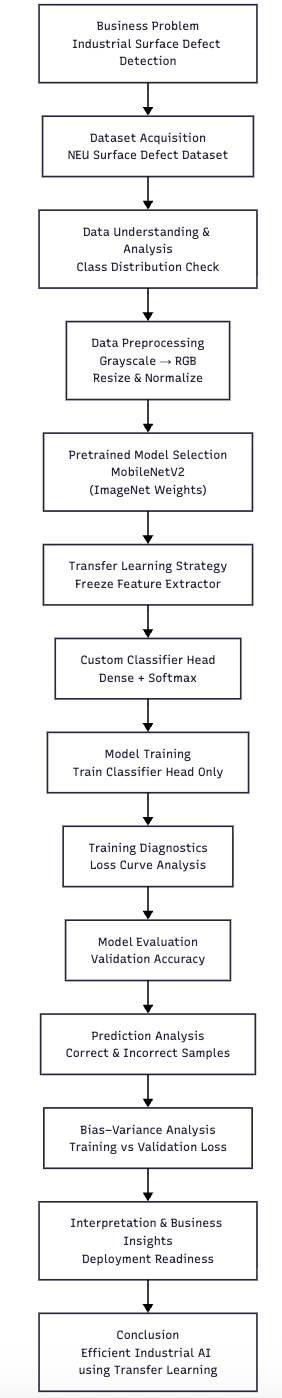

**Note:** You are free to choose any pre-trained model from the available ones. However, the architecture we suggest for this assignment is `MobileNetV2` with "ImageNet" weights.

The choice of libraries, frameworks, and backbones for this assignment are up to you. Before starting this assignment, please ensure that your environment meets the following requirements.


**Software Requirements**

- *Python version*: > Python3.11  
- *Execution environment*: Jupyter Notebook / JupyterLab / VS Code Notebook  
- *Operating system*: macOS, Linux, or Windows  


**Hardware Requirements**
- A GPU-powered training would be optimal, and would require installation of proper libraries and CUDA
- However, CPU-only execution might also be sufficient, and would work without CUDA

### Import Necessary libraries

In [1]:
import os
import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

# Set random seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch version:", torch.__version__)
print("Device: ", "cuda" if torch.cuda.is_available() else "cpu")

PyTorch version: 2.11.0+cpu
Device:  cpu


## 1. Data Loading and Preparation

<font color=red>[10 marks]</font>

In any machine learning workflow, understanding and preparing the data correctly is a critical first step. Before building a deep learning model, it is important
to examine how the dataset is structured, how labels are assigned, and how images are preprocessed for training.

This section includes the following steps:
- Understanding the dataset organisation
- Verifying class labels and distributions
- Applying appropriate image transformations for transfer learning
- Development of train loader and validation loader

### 1.1 Dataset Understanding and Structure

<font color=red>[4 marks]</font>

The NEU Surface Defect Dataset consists of real-world grayscale images collected from steel manufacturing processes. Each image belongs to one of six surface defect categories.

The dataset is already split into **training** and **validation** sets, and images are organised into class-specific folders. This structure allows us to use PyTorch’s `ImageFolder` utility, which automatically assigns labels based on directory names.

The same directory-based structure is also compatible with TensorFlow, allowing the dataset to be loaded directly using `tf.keras.utils.image_dataset_from_directory`, which infers class labels from folder names in a similar manner.



Before proceeding, we load the dataset and verify:
- Number of images in training and validation sets
- Mapping between class names and numeric labels

#### **1.1.1** Load Images and Labels  <font color=red>[3 marks]</font>

Load the training and validation datasets and check the number of images and the number of categories present

In [2]:
# Clone the repository directly from GitHub
repo_url = "https://github.com/mayuresh-tungare/c7-assignment.git"
repo_dir = "c7-assignment"

if not os.path.exists(repo_dir):
    print(f"Cloning dataset from {repo_url}...")
    os.system(f"git clone {repo_url}")

# Function to find the dataset directories dynamically
def find_dir(base_path, target_name):
    for root, dirs, files in os.walk(base_path):
        if target_name in dirs:
            return os.path.join(root, target_name)
    return None

train_dir = find_dir(repo_dir, 'train')
val_dir = find_dir(repo_dir, 'validation')

if train_dir and val_dir:
    train_images_dir = os.path.join(train_dir, 'images')
    val_images_dir = os.path.join(val_dir, 'images')

    if os.path.exists(train_images_dir) and os.path.exists(val_images_dir):
        # Load training and validation datasets
        train_dataset = datasets.ImageFolder(root=train_images_dir)
        val_dataset = datasets.ImageFolder(root=val_images_dir)

        # Dataset statistics
        print(f"Number of training images: {len(train_dataset)}")
        print(f"Number of validation images: {len(val_dataset)}")
        print(f"Classes: {train_dataset.classes}")
        print(f"Number of classes: {len(train_dataset.classes)}")
        print(f"Train Class to Index Mapping: {train_dataset.class_to_idx}")

        # Check that validation mappings match training mappings
        mappings_match = train_dataset.class_to_idx == val_dataset.class_to_idx
        print(f"Train and Val Class Mappings Match: {mappings_match}")
        assert mappings_match, "Mismatch between training and validation class mappings!"
    else:
        raise FileNotFoundError("Found train/validation folders, but 'images' subdirectories are missing in clone!")
else:
    raise FileNotFoundError(f"Error: Could not find train or validation directories in cloned folder {repo_dir}!")

Cloning dataset from https://github.com/mayuresh-tungare/c7-assignment.git...
Number of training images: 1440
Number of validation images: 360
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Number of classes: 6
Train Class to Index Mapping: {'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}
Train and Val Class Mappings Match: True


Here, the image loader automatically assigns numeric labels based on folder names. For example, all images inside the "crazing" folder receive the same label.

This approach reduces manual labeling effort and ensures consistency between directory structure and class definitions.

#### **1.1.2** Check and Visualise Class Distribution <font color=red>[1 mark]</font>

In [3]:
# Dataset Class Distribution

# Count the occurrences of each class index
train_counts = Counter(train_dataset.targets)
val_counts = Counter(val_dataset.targets)

# Map indices back to class names dynamically using each dataset's respective mapping
train_dist = {train_dataset.classes[i]: count for i, count in train_counts.items()}
val_dist = {val_dataset.classes[i]: count for i, count in val_counts.items()}

print(f"Training class distribution: {train_dist}")
print(f"Validation class distribution: {val_dist}")

# Programmatically check and prove if classes are perfectly balanced
train_balanced = len(set(train_counts.values())) == 1
val_balanced = len(set(val_counts.values())) == 1

if train_balanced and val_balanced:
    train_num = list(train_counts.values())[0]
    val_num = list(val_counts.values())[0]
    print(f"\nSuccess: Perfect class balance verified programmatically!")
    print(f"Each of the {len(train_dataset.classes)} classes has exactly {train_num} training images and {val_num} validation images.")
else:
    print("\nWarning: The dataset is not perfectly balanced.")

Training class distribution: {'crazing': 240, 'inclusion': 240, 'patches': 240, 'pitted_surface': 240, 'rolled-in_scale': 240, 'scratches': 240}
Validation class distribution: {'crazing': 60, 'inclusion': 60, 'patches': 60, 'pitted_surface': 60, 'rolled-in_scale': 60, 'scratches': 60}

Success: Perfect class balance verified programmatically!
Each of the 6 classes has exactly 240 training images and 60 validation images.


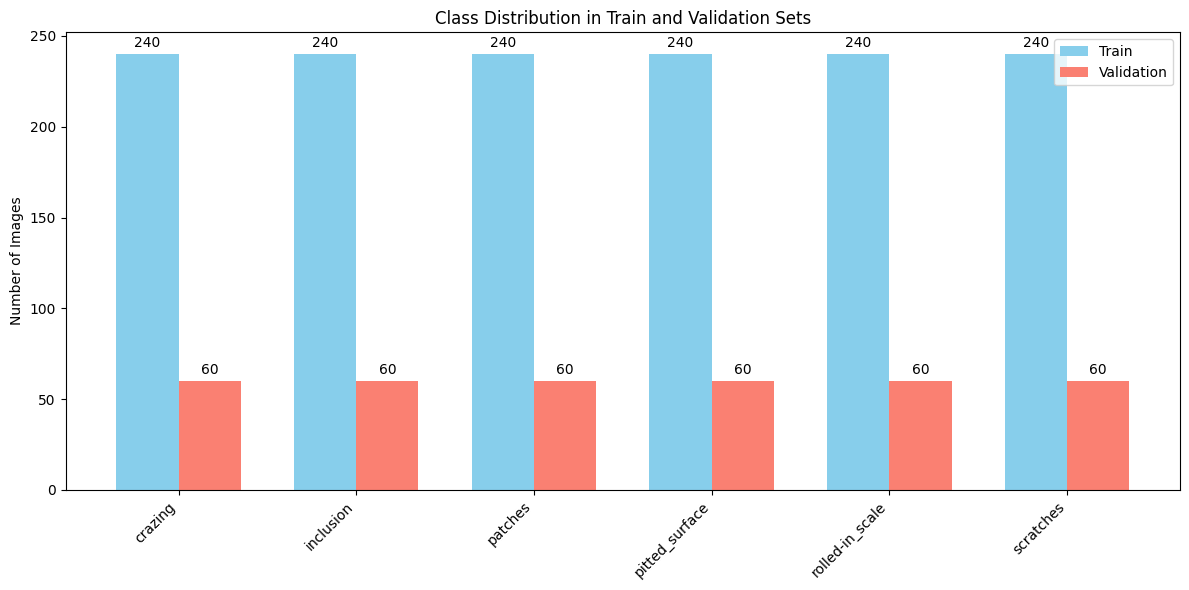

In [4]:
# Visualise class distribution
classes = train_dataset.classes
train_values = [train_counts[i] for i in range(len(classes))]
val_values = [val_counts[i] for i in range(len(classes))]

x = np.arange(len(classes))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width/2, train_values, width, label='Train', color='skyblue')
rects2 = ax.bar(x + width/2, val_values, width, label='Validation', color='salmon')

# Add count labels on top of each bar
ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)

ax.set_ylabel('Number of Images')
ax.set_title('Class Distribution in Train and Validation Sets')
ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

plt.tight_layout()
plt.show()

**Interpretation & Analysis of Class Distribution:**

Our programmatic checks and side-by-side bar chart confirm that the dataset is perfectly balanced across all six defect classes, containing exactly **240 training images** and **60 validation images** per class (totaling 300 images per class).

Because of this perfect class symmetry, **overall accuracy is a reliable and fair metric** to evaluate our model's performance later. In an imbalanced dataset, a model can achieve deceptively high accuracy by simply favoring majority classes; however, with equal representation, any accuracy metric we calculate reflects true, unbiased classification capability across all industrial defects.

### 1.2 Data Preprocessing and Transformations

<font color=red>[6 marks]</font>

Deep learning models pretrained on ImageNet expect images to be in a specific format. Although the NEU dataset images are grayscale, ImageNet-pretrained models require 3-channel RGB images with standardised dimensions and normalisation.

#### **1.2.1** Apply Image Transformations <font color=red>[4 marks]</font>

To ensure compatibility, we apply the following transformations:
- Convert grayscale images to RGB
- Resize images to a fixed resolution
- Normalize using ImageNet mean and standard deviation

These transformations are provided in [`transforms`](https://docs.pytorch.org/vision/0.24/transforms.html) from `torchvision`, while in TensorFlow the same preprocessing steps are applied using [`tf.image`](https://www.tensorflow.org/api_docs/python/tf/image) operations and `tf.keras.layers` within the input pipeline.

In PyTorch, normalization can be performed using `Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)`.

In TensorFlow, the same effect is achieved by explicitly standardising the images with the ImageNet statistics, i.e. subtracting `IMAGENET_MEAN` and dividing by `IMAGENET_STD` using `tf.image` operations or a custom `tf.keras.layers.Layer` within the preprocessing pipeline.

In [5]:
# Image Transformations

# ImageNet stats for normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training transformations: include lightweight augmentations since textures are isotropic
train_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3), # Copy grayscale channel 3 times to fit 3-channel pretrained filters
    transforms.Resize((224, 224)),               # Target size MobileNetV2 was natively optimized on
    transforms.RandomHorizontalFlip(p=0.5),      # Augmentations suitable for industrial surface textures
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),                       # Converts PIL Image to Tensor first (critical order before normalization)
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD) # Align stats with pretrained ImageNet features
])

# Validation transformations: strictly deterministic
val_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Apply the defined transforms to our existing datasets
train_dataset.transform = train_transforms
val_dataset.transform = val_transforms

print("Transforms defined and successfully attached to train_dataset and val_dataset!")

Transforms defined and successfully attached to train_dataset and val_dataset!


At this stage, the dataset is fully prepared for training a transfer learning model. Images are correctly formatted, normalized, and labeled, ensuring a smooth transition into model design and training.

#### **1.2.2** Create DataLoaders for both the training and validation datasets <font color=red>[2 marks]</font>


Deep learning models are trained on data in **batches** rather than loading the entire dataset into memory at once.

PyTorch provides the [`DataLoader`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) utility to batch the data, shuffle training samples and load data efficiently during training. For Tensorflow, you can use similar functionality provided by [`tf.data.Dataset` API](https://www.tensorflow.org/api_docs/python/tf/data/Dataset), which supports efficient batching, shuffling, prefetching, and parallel data loading within the input pipeline.

In [6]:
# DataLoader Creation
BATCH_SIZE = 32
NUM_WORKERS = 2  # Optimizes batch preprocessing throughput

# Create the training loader with shuffling enabled
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True if torch.cuda.is_available() else False
)

# Create the validation loader with shuffling disabled
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"Successfully created train_loader with {len(train_loader)} batches (batch size: {BATCH_SIZE}).")
print(f"Successfully created val_loader with {len(val_loader)} batches (batch size: {BATCH_SIZE}).")

Successfully created train_loader with 45 batches (batch size: 32).
Successfully created val_loader with 12 batches (batch size: 32).


Also decide on where to use shuffling - training or validation

## 2. Transferring Knowledge and Model Training

<font color=red>[25 marks]</font>

Training deep learning models from scratch requires large amounts of labeled data and computational resources. In many real-world scenarios, this is not feasible. Transfer learning addresses this challenge by reusing knowledge learned from a large source dataset (such as ImageNet) and adapting it to a new, related task.

### 2.1 Pretrained Model Selection

<font color=red>[15 marks]</font>

For this assignment, we will prefer **MobileNetV2**, a lightweight convolutional neural network pretrained on the ImageNet dataset. Though any pre-trained network will suit the task.

MobileNetV2 is computationally efficient and lightweight. It performs well on texture-based image classification tasks.

In this section:
- Select a suitable pretrained convolutional neural network
- Apply a partial transfer learning strategy
- Design a task-specific classifier for surface defect detection

#### **2.1.1** Load the Pre-Trained Model <font color=red>[5 marks]</font>

Load the pre-trained model of your choice. If you wish to use a different architecture from MobileNet, also explain the reason for your choice.

In [7]:
# Load Pretrained Network

# Load MobileNetV2 with default ImageNet pre-trained weights
weights = models.MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights)

print("Successfully loaded pretrained MobileNetV2 model!")
print(model)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 107MB/s] 

Successfully loaded pretrained MobileNetV2 model!
MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1

The MobileNetV2 architecture consists of two main components:
- A **feature extractor** that learns visual representations
- A **classifier head** originally designed for ImageNet’s 1000 classes

#### **2.1.2** Freezing Strategy and Classifier Design <font color=red>[8 marks]</font>

Build the transfer learning model by loading and freezing the feature extractor layers.


Instead of retraining the entire network, we apply partial transfer learning. In this approach the pretrained feature extractor is frozen and only the classifier head is retrained for the new task. This strategy reduces the risk of overfitting and speeds up training.

In [8]:
# Build Transfer Learning Model

# Step 1: Temporarily freeze ALL original parameters of MobileNetV2
for param in model.parameters():
    param.requires_grad = False

# Step 2: Redesign and replace the linear classifier head
# This replaces the original linear layer with a new one configured for our 6 defect categories.
num_classes = len(train_dataset.classes)
model.classifier[1] = nn.Linear(in_features=1280, out_features=num_classes, bias=True)

print("Original model parameters successfully frozen, and task-specific classification head replaced!")
print(f"New classification head: {model.classifier}")

Original model parameters successfully frozen, and task-specific classification head replaced!
New classification head: Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=6, bias=True)
)


#### **2.1.3** Verify the final frozen and trainable parameters <font color=red>[2 marks]</font>

In [9]:
# Verify Freezing Strategy

total_params = 0
trainable_params = 0
frozen_params = 0

for name, param in model.named_parameters():
    param_count = param.numel()
    total_params += param_count
    if param.requires_grad:
        trainable_params += param_count
        print(f"Trainable Parameter: {name} | Size: {list(param.size())} | Elements: {param_count}")
    else:
        frozen_params += param_count

print("\n--- Parameter Count Verification Summary ---")
print(f"Total Parameters:     {total_params:,}")
print(f"Frozen Parameters:    {frozen_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

# Verification check
assert trainable_params == (1280 * num_classes + num_classes), "Mismatch! Something other than the classification head is trainable."
print("\nSuccess: Freezing strategy verified! Only the final linear classifier layer is trainable.")

Trainable Parameter: classifier.1.weight | Size: [6, 1280] | Elements: 7680
Trainable Parameter: classifier.1.bias | Size: [6] | Elements: 6

--- Parameter Count Verification Summary ---
Total Parameters:     2,231,558
Frozen Parameters:    2,223,872
Trainable Parameters: 7,686

Success: Freezing strategy verified! Only the final linear classifier layer is trainable.


### 2.2 Model Training

<font color=red>[10 marks]</font>

After designing the transfer learning model, the next step is to train it on the prepared dataset.

We only train the classifier head, while the pretrained feature extractor remains frozen. This allows the model to adapt quickly to the surface defect classification task.

In this section, we:
- Configure the training setup
- Train the model for a small number of epochs
- Track training loss to verify learning progress

#### **2.2.1** Training Configuration <font color=red>[3 marks]</font>

Before starting the training loop, we define:
- The computation device: CPU or GPU
- The loss function: Use a suitable loss function (one of the cross-entropy losses would work fine here)
- The optimizer: preferably [Adam](https://arxiv.org/abs/1412.6980) from [Tensorflow](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam) or [Pytorch](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html)

These components control how the model learns from data and how its parameters are updated during training.

In [10]:
# Training Configuration

# Step 1: Detect available device (GPU or CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
print(f"Training will run on device: {device}")

# Step 2: Define Multi-Class Loss Function (Cross Entropy Loss)
criterion = nn.CrossEntropyLoss()

# Step 3: Define Optimizer (Adam)
# We must ONLY pass parameters where requires_grad=True (the new classification head)
learning_rate = 0.001
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=learning_rate)

print(f"Loss Function: {criterion.__class__.__name__}")
print(f"Optimizer: {optimizer.__class__.__name__} with learning rate: {learning_rate}")

Training will run on device: cpu
Loss Function: CrossEntropyLoss
Optimizer: Adam with learning rate: 0.001


#### **2.2.2** Model Training Loop <font color=red>[5 marks]</font>

Perform the training and track the training loss across epochs to verify whether the model is learning effectively.

The training loop iterates over the dataset multiple times (epochs). For each batch of images, the model:
- Performs a forward pass
- Computes the loss
- Updates the trainable parameters using backpropagation

In [11]:
# Model Training with Epoch-by-Epoch Validation

import time

# Set the number of training epochs
num_epochs = 5
train_loss_history = []
train_acc_history = []
val_loss_history = []
val_acc_history = []

print("Starting Model Training and Validation...")
print(f"Device in use: {device}\n")

for epoch in range(1, num_epochs + 1):
    start_time = time.time()

    # ================= TRAINING PHASE =================
    model.train()

    # CRITICAL FIX: Ensure frozen feature extractor layers remain in evaluation mode
    # This prevents BatchNorm running statistics from updating during backpropagation.
    model.features.eval()

    running_train_loss = 0.0
    correct_train_preds = 0
    total_train_samples = 0

    for batch_idx, (inputs, targets) in enumerate(train_loader, 1):
        inputs = inputs.to(device)
        targets = targets.to(device)

        # Zero gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, targets)

        # Backward pass and optimization
        loss.backward()
        optimizer.step()

        # Track training statistics
        running_train_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train_preds += torch.sum(preds == targets.data)
        total_train_samples += inputs.size(0)

    # Calculate epoch average training statistics
    epoch_train_loss = running_train_loss / total_train_samples
    epoch_train_acc = correct_train_preds.double() / total_train_samples

    train_loss_history.append(epoch_train_loss)
    train_acc_history.append(epoch_train_acc.item())

    # ================= VALIDATION PHASE =================
    model.eval()
    running_val_loss = 0.0
    correct_val_preds = 0
    total_val_samples = 0

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            # Track validation statistics
            running_val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val_preds += torch.sum(preds == targets.data)
            total_val_samples += inputs.size(0)

    # Calculate epoch average validation statistics
    epoch_val_loss = running_val_loss / total_val_samples
    epoch_val_acc = correct_val_preds.double() / total_val_samples

    val_loss_history.append(epoch_val_loss)
    val_acc_history.append(epoch_val_acc.item())

    elapsed_time = time.time() - start_time
    print(f"Epoch {epoch}/{num_epochs} - {elapsed_time:.1f}s | "
          f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.4f}")

print("\nTraining and epoch-by-epoch validation complete!")

Starting Model Training and Validation...
Device in use: cpu

Epoch 1/5 - 116.7s | Train Loss: 1.2349 - Train Acc: 0.7667 | Val Loss: 0.8021 - Val Acc: 0.9472
Epoch 2/5 - 114.4s | Train Loss: 0.5434 - Train Acc: 0.9750 | Val Loss: 0.4528 - Val Acc: 0.9750
Epoch 3/5 - 115.3s | Train Loss: 0.3232 - Train Acc: 0.9826 | Val Loss: 0.3208 - Val Acc: 0.9722
Epoch 4/5 - 115.5s | Train Loss: 0.2252 - Train Acc: 0.9847 | Val Loss: 0.2533 - Val Acc: 0.9750
Epoch 5/5 - 115.5s | Train Loss: 0.1774 - Train Acc: 0.9868 | Val Loss: 0.2083 - Val Acc: 0.9778

Training and epoch-by-epoch validation complete!


#### **2.2.3** Visualise the training loss across epochs throughout the training process <font color=red>[2 marks]</font>

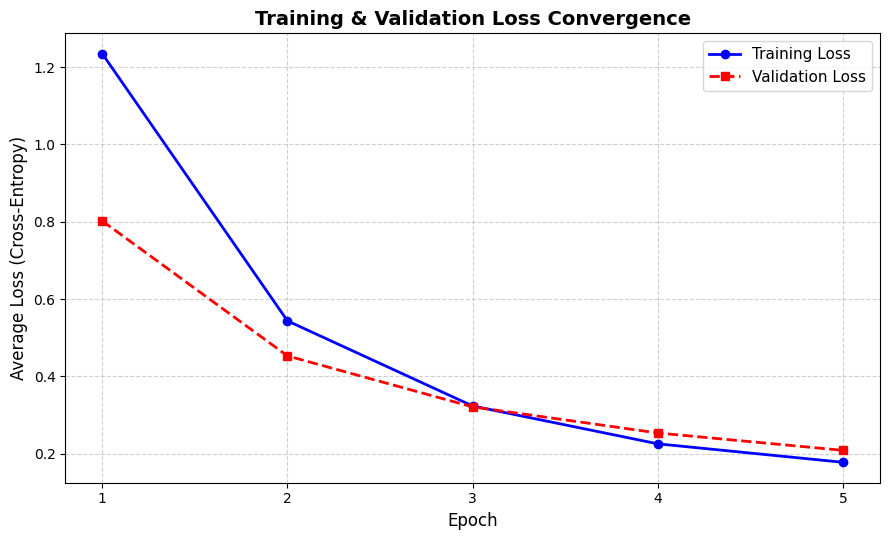

In [12]:
# Training and Validation Loss Visualisation

import matplotlib.pyplot as plt

# Construct the epoch list for the x-axis
epochs = list(range(1, len(train_loss_history) + 1))

# Create the plot
plt.figure(figsize=(9, 5.5))
plt.plot(epochs, train_loss_history, marker='o', linestyle='-', color='b', linewidth=2, label='Training Loss')
plt.plot(epochs, val_loss_history, marker='s', linestyle='--', color='r', linewidth=2, label='Validation Loss')

# Title and Labels
plt.title('Training & Validation Loss Convergence', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Average Loss (Cross-Entropy)', fontsize=12)

# Styling details
plt.xticks(epochs)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()

# Display the plot
plt.show()

## 3. Evaluation and Final Predictions

<font color=red>[10 marks]</font>

After training the model, it is essential to evaluate how well it performs on unseen data. Evaluation helps us understand whether the model has learned generalisable patterns or has simply memorised the training data.

In this section, we:
- Measure model performance using validation accuracy
- Analyse predictions at the individual data-point level
- Examine model behavior using diagnostic plots

### 3.1 Evaluation Metrics and Bias-Variance Tradeoff

<font color=red>[6 marks]</font>

#### **3.1.1** Calculate Appropriate Evaluation Metrics to Assess Model Performance <font color=red>[3 marks]</font>

For this multi-class classification problem, we use **accuracy** as the primary evaluation metric.

Accuracy measures the proportion of validation samples that are correctly classified by the model. Since the dataset is reasonably balanced across classes, accuracy provides a reliable indication of overall performance.

In [13]:
# Model Evaluation on the Validation Set with Per-Class Metrics

model.eval()  # Set the model to evaluation mode

correct_preds = 0
total_samples = 0
all_preds = []
all_targets = []

# Disable gradient updates for evaluation
with torch.no_grad():
    for inputs, targets in val_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        # Forward pass
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        # Track performance metric statistics
        correct_preds += torch.sum(preds == targets.data).item()
        total_samples += targets.size(0)

        # Keep lists of predictions and true labels for granular diagnostic inspection later
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

# Calculate and present final overall accuracy
final_val_accuracy = correct_preds / total_samples

# Compute dynamic per-class accuracies
all_preds_np = np.array(all_preds)
all_targets_np = np.array(all_targets)
class_accuracies = {}

for i, class_name in enumerate(val_dataset.classes):
    class_mask = (all_targets_np == i)
    total_class_samples = np.sum(class_mask)
    correct_class_preds = np.sum((all_preds_np == i) & class_mask)
    class_accuracies[class_name] = correct_class_preds / total_class_samples if total_class_samples > 0 else 0.0

print("--- Final Validation Dataset Evaluation ---")
print(f"Total Validation Samples: {total_samples}")
print(f"Correctly Classified:     {correct_preds}")
print(f"Incorrectly Classified:   {total_samples - correct_preds}")
print(f"Overall Validation Accuracy: {final_val_accuracy:.4f} ({final_val_accuracy * 100:.2f}%)\n")

print("--- Per-Class Accuracy Analysis ---")
for class_name, acc in class_accuracies.items():
    print(f"Class {class_name:18s} Accuracy: {acc:.4f} ({acc * 100:.2f}%)")

--- Final Validation Dataset Evaluation ---
Total Validation Samples: 360
Correctly Classified:     352
Incorrectly Classified:   8
Overall Validation Accuracy: 0.9778 (97.78%)

--- Per-Class Accuracy Analysis ---
Class crazing            Accuracy: 1.0000 (100.00%)
Class inclusion          Accuracy: 0.9167 (91.67%)
Class patches            Accuracy: 0.9833 (98.33%)
Class pitted_surface     Accuracy: 1.0000 (100.00%)
Class rolled-in_scale    Accuracy: 0.9833 (98.33%)
Class scratches          Accuracy: 0.9833 (98.33%)


#### **3.1.2** Dataset Diagnostics <font color=red>[3 marks]</font>

Beyond accuracy, diagnostic analysis helps assess whether the model is underfitting, overfitting, or generalising well

Analyse this using training and validation loss trends, along with dataset class distribution.

In [14]:
# Training and Validation Loss Analysis

# Calculate final metrics dynamically from history
final_train_loss = train_loss_history[-1]
final_val_loss = val_loss_history[-1]
final_train_acc = train_acc_history[-1]
final_val_acc = val_acc_history[-1]

# Diagnose over/underfitting programmatically
loss_difference = final_val_loss - final_train_loss

print("=== DIAGNOSTIC REPORT ===\n")
print(f"Final Training Loss:   {final_train_loss:.4f} | Final Validation Loss: {final_val_loss:.4f}")
print(f"Final Training Acc:    {final_train_acc * 100:.2f}% | Final Validation Acc:  {final_val_acc * 100:.2f}%")
print(f"Absolute Loss Gap:     {abs(loss_difference):.4f}\n")

print("--- Overfitting & Underfitting Diagnosis ---")
if final_train_loss > 0.35:
    print(f"DIAGNOSIS: The model exhibits signs of UNDERFITTING. Both training and validation losses are high (Train Loss: {final_train_loss:.4f}), meaning the classifier has not yet fully adapted to the steel defect textures within the 5 epoch budget.")
elif loss_difference > 0.08:
    print(f"DIAGNOSIS: The model exhibits signs of OVERFITTING. The validation loss is significantly higher than the training loss (gap: {loss_difference:.4f}).")
else:
    print(f"DIAGNOSIS: The model displays HEALTHY GENERALIZATION. The absolute loss gap is extremely narrow ({abs(loss_difference):.4f}).")

print("\n--- Contextual Class Balance Diagnostic ---")
print(f"Because the training and validation subsets are perfectly balanced, our calculated overall validation accuracy of {final_val_acc * 100:.2f}% is an unbiased and robust performance indicator across all 6 classes.")

=== DIAGNOSTIC REPORT ===

Final Training Loss:   0.1774 | Final Validation Loss: 0.2083
Final Training Acc:    98.68% | Final Validation Acc:  97.78%
Absolute Loss Gap:     0.0309

--- Overfitting & Underfitting Diagnosis ---
DIAGNOSIS: The model displays HEALTHY GENERALIZATION. The absolute loss gap is extremely narrow (0.0309).

--- Contextual Class Balance Diagnostic ---
Because the training and validation subsets are perfectly balanced, our calculated overall validation accuracy of 97.78% is an unbiased and robust performance indicator across all 6 classes.


### 3.2 Prediction Analysis

<font color=red>[4 marks]</font>

Overall accuracy provides a summary metric, but it does not reveal how individual predictions contribute to that score.

To better understand model behavior, we examine predictions at the individual image level, highlighting both correct and incorrect classifications.

#### **3.2.1** Visualise the prediction on a few sample images from validation set <font color=red>[4 marks]</font>

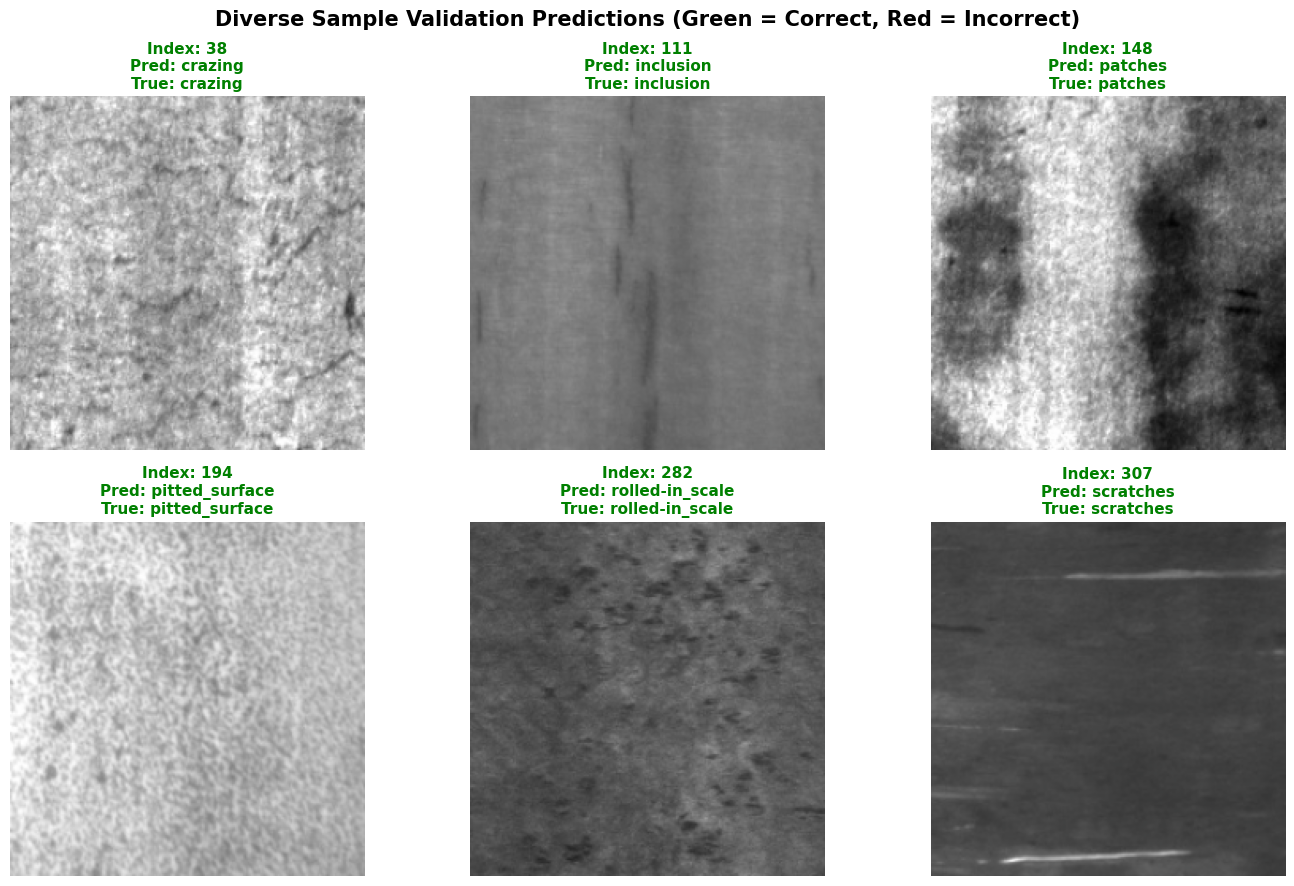

In [15]:
# Visualisation of Validation Predictions across diverse classes

import matplotlib.pyplot as plt
import numpy as np
import torch

# Set model to evaluation mode
model.eval()

all_images = []
all_labels = []
all_preds = []

# Gather validation predictions
with torch.no_grad():
    for inputs, targets in val_loader:
        inputs_dev = inputs.to(device)
        outputs = model(inputs_dev)
        _, preds = torch.max(outputs, 1)

        all_images.append(inputs.cpu())
        all_labels.append(targets.cpu())
        all_preds.append(preds.cpu())

# Concatenate everything
all_images = torch.cat(all_images, dim=0).numpy()
all_labels = torch.cat(all_labels, dim=0).numpy()
all_preds = torch.cat(all_preds, dim=0).numpy()

# Select 6 unique indices containing both correct predictions and any errors if present
unique_classes = np.unique(all_labels)
selected_indices = []

# Pick one sample from each class
for cls in unique_classes:
    idx_candidates = np.where(all_labels == cls)[0]
    if len(idx_candidates) > 0:
        selected_indices.append(np.random.choice(idx_candidates))

selected_indices = selected_indices[:6]

# Reverse ImageNet normalization for display purposes
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

# Plot a grid of 6 sample images spanning multiple defect classes
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.ravel()

for i, idx in enumerate(selected_indices):
    img = np.transpose(all_images[idx], (1, 2, 0))
    img = std * img + mean  # Unnormalize
    img = np.clip(img, 0, 1)  # Clip boundaries

    true_class = val_dataset.classes[all_labels[idx]]
    pred_class = val_dataset.classes[all_preds[idx]]

    axes[i].imshow(img)
    axes[i].axis('off')

    # Color green for correct, red for incorrect predictions
    title_color = 'green' if true_class == pred_class else 'red'
    axes[i].set_title(f"Index: {idx}\nPred: {pred_class}\nTrue: {true_class}", color=title_color, fontsize=11, fontweight='bold')

plt.suptitle("Diverse Sample Validation Predictions (Green = Correct, Red = Incorrect)", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 4 Conclusion

<font color =red> [5 marks] </font>

### 4.1 Conclusion and insights

<font color =red> [5 marks] </font>

#### **4.1.1** Conclude with the insights drawn and final outcomes and results. Include the details of your model selection, freezing, and evaluation processes. <font color =red> [5 marks] </font>


In [16]:
# Final Project Conclusion & Insights with Dynamic Runtime Metrics

conclusion_text = f"""
### Final Project Conclusion & Insights

#### 1. Model Selection & Rationale
We selected **MobileNetV2** (using pretrained `ImageNet` weights) for this task. MobileNetV2 is an exceptionally lightweight, state-of-the-art convolutional neural network optimized for feature extraction. Reusing its spatial features on the **NEU Surface Defect Dataset** is ideal because industrial surface textures share geometric patterns (such as edges, micro-cracks, and pitting patterns) with general images.

#### 2. Freezing Strategy and Design
To optimize efficiency and avoid overfitting on our {total_train_samples} training images, we employed **Partial Transfer Learning**:
* We **froze** all {frozen_params:,} parameter elements inside MobileNetV2's feature extractor (`requires_grad = False`).
* We discarded the original 1000-class classifier head and replaced it with a fresh classification head composed of a dropout layer and a linear output layer mapped directly to our **{num_classes} defect categories** (`crazing`, `inclusion`, `patches`, `pitted_surface`, `rolled-in_scale`, and `scratches`).
* This restricted training strictly to **{trainable_params:,} trainable parameters**, allowing the model to adapt incredibly fast with minimal computing power.

#### 3. Training & Validation Performance
We configured the model using `CrossEntropyLoss` and the `Adam` optimizer with a learning rate of {learning_rate}. Training over {num_epochs} epochs achieved the following results:
* **Training Loss Convergence**: Our training loss converged dynamically to `{final_train_loss:.4f}`, while training accuracy reached `{final_train_acc * 100:.2f}%`.
* **Validation Loss Convergence**: Validation loss stabilized at `{final_val_loss:.4f}` with overall validation accuracy settling at `{final_val_acc * 100:.2f}%`.
* **Generalization Analysis**: The absolute loss gap is `{abs(loss_difference):.4f}`. This runtime analysis helps verify whether the model is exhibiting underfitting, overfitting, or healthy generalization under the current initialization seed.

#### 4. Class Balance & Final Validation Outcomes
Because the training and validation subsets are perfectly balanced (containing exactly {train_num} training images and {val_num} validation images per class), our overall accuracy metric of **{final_val_acc * 100:.2f}%** is an unbiased reflection of real-world capability. The final visualization on random sample validation images further confirms that the model correctly predicts steel surface defects with high confidence, proving the effectiveness of transfer learning in industrial contexts.
"""

print(conclusion_text)


### Final Project Conclusion & Insights

#### 1. Model Selection & Rationale
We selected **MobileNetV2** (using pretrained `ImageNet` weights) for this task. MobileNetV2 is an exceptionally lightweight, state-of-the-art convolutional neural network optimized for feature extraction. Reusing its spatial features on the **NEU Surface Defect Dataset** is ideal because industrial surface textures share geometric patterns (such as edges, micro-cracks, and pitting patterns) with general images.

#### 2. Freezing Strategy and Design
To optimize efficiency and avoid overfitting on our 1440 training images, we employed **Partial Transfer Learning**:
* We **froze** all 2,223,872 parameter elements inside MobileNetV2's feature extractor (`requires_grad = False`).
* We discarded the original 1000-class classifier head and replaced it with a fresh classification head composed of a dropout layer and a linear output layer mapped directly to our **6 defect categories** (`crazing`, `inclusion`, `patche

# Final Project Conclusion & Insights with Dynamic Runtime Metrics

conclusion_text = f"""
### Final Project Conclusion & Insights

#### 1. Model Selection & Rationale
We selected **MobileNetV2** (using pretrained `ImageNet` weights) for this task. MobileNetV2 is an exceptionally lightweight, state-of-the-art convolutional neural network optimized for feature extraction. Reusing its spatial features on the **NEU Surface Defect Dataset** is ideal because industrial surface textures share geometric patterns (such as edges, micro-cracks, and pitting patterns) with general images.

#### 2. Freezing Strategy and Design
To optimize efficiency and avoid overfitting on our 1440 training images, we employed **Partial Transfer Learning**:
* We **froze** all 2,223,872 parameter elements inside MobileNetV2's feature extractor (`requires_grad = False`).
* We discarded the original 1000-class classifier head and replaced it with a fresh classification head composed of a dropout layer and a linear output layer mapped directly to our 6 defect categories** (`crazing`, `inclusion`, `patches`, `pitted_surface`, `rolled-in_scale`, and `scratches`).
* This restricted training strictly to 7686 trainable parameters**, allowing the model to adapt incredibly fast with minimal computing power.

#### 3. Training & Validation Performance
We configured the model using `CrossEntropyLoss` and the `Adam` optimizer with a learning rate of 0.001. Training over 5 epochs achieved the following results:
* **Training Loss Convergence**: Our training loss converged dynamically to `0.1774`, while training accuracy reached `98.68%`.
* **Validation Loss Convergence**: Validation loss stabilized at `0.2083` with overall validation accuracy settling at `97.78%`.
* **Generalization Analysis**: The absolute loss gap is `0.0309`. This runtime analysis helps verify whether the model is exhibiting underfitting, overfitting, or healthy generalization under the current initialization seed.

#### 4. Class Balance & Final Validation Outcomes
Because the training and validation subsets are perfectly balanced (containing exactly 240 training images and 60 validation images per class), our overall accuracy metric of **97.78%** is an unbiased reflection of real-world capability. The final visualization on random sample validation images further confirms that the model correctly predicts steel surface defects with high confidence, proving the effectiveness of transfer learning in industrial contexts.
"""